# Chọn vị trí trạm sạc xe điện bằng GIS: mở rộng nhiều quận Hà Nội

Bản 2 của `tram_sac_xe_dien.ipynb`. Cùng quy trình chấm điểm, nhưng chạy **cho nhiều quận cùng lúc**, mỗi quận có lưới ô 250 m riêng, và thêm bước **đề xuất cho cả Hà Nội**. Chạy từ trên xuống dưới. Mở bằng môi trường `evgis`, từ **thư mục gốc của dự án** (nơi có file này).

| Phần | Việc làm | Ghi ra |
|---|---|---|
| 0 | Sửa DLL của môi trường, nạp thư viện, cài đặt, danh sách quận | |
| 1 | Ranh giới từng quận (tìm trên OSM, kiểm tra diện tích) | `du_lieu/hn/<quận>/area.gpkg` |
| 2 | Dữ liệu OpenStreetMap theo quận, trạm sạc nhập tay | `du_lieu/hn/<quận>/*.gpkg` |
| 3 | Dân số WorldPop | `du_lieu/hn/pop_clip.tif` |
| 4 | Lưới 250 m chung, mỗi ô thuộc đúng một quận, và 5 tiêu chí | biến `grid` |
| 5 | Chuẩn hóa về thang 0-1 | cột `n_*` |
| 6 | Trọng số AHP | biến `w` |
| 7 | Chấm điểm, độ nhạy, kiểm chứng | cột `score`, `rank`, `rank_city` |
| 8 | Tổng hợp theo quận, đề xuất cho cả Hà Nội, xuất báo cáo | `ket_qua/hn_*` |
| 9 | Xuất dữ liệu cho trò chơi nhiều quận | `tro_choi_hn/data/` |

**Quy tắc dùng (giống bản 1):**
- Mỗi lần Restart kernel, chạy lại từ ô đầu tiên (các bước tải về tự bỏ qua nếu file đã có).
- Mọi lựa chọn chỉnh được nằm ở ô **Cài đặt** ở phần 0, đừng sửa rải rác trong các ô sau.
- **Thêm quận mới:** chỉ cần thêm một dòng vào `DISTRICTS` rồi chạy lại. Quận cũ không bị tải lại, chỉ quận mới được tải.

**Khác bản 1 (có lý do):**
- Dữ liệu OSM tải theo từng quận, có **vùng đệm `BUFFER_M`** quanh quận, vì ô sát ranh giới cần đếm chung cư, điểm đến trong 500 m và tìm đường trục, trạm sạc gần nhất nằm ngoài quận.
- Lưới là **một lưới chung** căn theo bội số của 250 m, mỗi ô thuộc quận có phần diện tích chồng lớn nhất. Hai quận kề nhau không có ô trùng.
- Mặc định chuẩn hóa **chung cho cả thành phố** (`NORM_SCOPE = "all"`) để điểm của các quận so sánh được với nhau.

## 0. Môi trường và cài đặt

**Ô 1: sửa lỗi kernel chết trên Windows.** Ép Python dùng đúng DLL của `evgis` thay vì DLL của PostgreSQL/QGIS. Luôn chạy ô này trước tiên.

In [6]:
# Ép sử dụng thư viện DLL của evgis (tránh kernel chết do xung đột DLL trên Windows)
import os, sys
import pyproj

env = sys.prefix                                   # thư mục môi trường evgis
lib = os.path.join(env, "Library")
os.environ["GDAL_DATA"] = os.path.join(lib, "share", "gdal")
os.environ["PROJ_DATA"] = pyproj.datadir.get_data_dir()
os.environ["PROJ_LIB"]  = os.environ["PROJ_DATA"]

# Đưa DLL của evgis lên đầu PATH, bỏ các thư mục dễ gây xung đột
mine = [env, os.path.join(lib, "bin"), os.path.join(lib, "mingw-w64", "bin"), os.path.join(env, "Scripts")]
rest = [p for p in os.environ["PATH"].split(os.pathsep)
        if not any(k in p.lower() for k in ("postgres", "qgis", "osgeo4w"))]
os.environ["PATH"] = os.pathsep.join(mine + rest)
print("Môi trường:", env)

Môi trường: c:\Users\DINHDUY_LAPTOP\anaconda3\envs\evgis


**Ô 2: nạp thư viện và cài đặt.** Mọi lựa chọn chỉnh được nằm ở đây, kể cả **danh sách quận**. Cột `km2` là khoảng diện tích chấp nhận được để máy tự kiểm tra ranh giới tìm được trên OSM có đúng quận không (diện tích chính thức: Bắc Từ Liêm 43,4; Nam Từ Liêm 32,2; Hà Đông 49,6; Ba Đình 9,2; Đống Đa 10,0; Hai Bà Trưng 10,3; Hoàng Mai 40,3; Thanh Trì 63,2 km²).

In [7]:
import os, json, time
import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import requests
import rasterio
from rasterio.mask import mask
from rasterstats import zonal_stats
from shapely.geometry import box
from shapely import STRtree
import matplotlib.pyplot as plt

# ===================== CÀI ĐẶT =====================
CRS = 32648                # UTM 48N, đơn vị mét, dùng cho mọi phép tính khoảng cách
SIZE = 250                 # cạnh ô lưới (m)
LOG_TRANSFORM = True       # dùng log1p cho dân số, chung cư, điểm đến (dữ liệu lệch phải nặng)
BUFFER_M = 1000            # vùng đệm quanh mỗi quận khi tải OSM (m): ô sát ranh giới cần dữ liệu bên ngoài quận
NORM_SCOPE = "all"         # "all": chuẩn hóa chung cho mọi quận (so sánh được giữa các quận)
                           # "district": chuẩn hóa riêng từng quận (chỉ so sánh trong nội bộ quận)
MIN_OVERLAP = 0.0          # bỏ ô có phần nằm trong quận nhỏ hơn tỷ lệ này (0.05 = 5% diện tích ô); 0 = giữ như bản 1

# Overpass chỉ chấp nhận client tự xưng danh: đặt tên dự án + liên hệ THẬT của bạn,
# KHÔNG giả làm trình duyệt (Mozilla/5.0...) vì sẽ bị trả mã 406.
UA = "tram-sac-xe-dien/2.0 (bai tap mon GIS; lien he: nguyendinhduy257@gmail.com)"

HAND_DRAWN = []            # danh sách mã quận dùng file vẽ tay du_lieu/hn/<mã>/area_hand.geojson, ví dụ ["thanh_tri"]
FORCE_AREA = False         # True: tìm lại ranh giới mọi quận dù đã có area.gpkg
FORCE_OSM = False          # True: tải lại dữ liệu OSM dù đã có (nhớ chạy lại ô gộp trạm sạc)
FORCE_POP = False          # True: cắt lại dân số dù đã có pop_clip.tif
DOWNLOAD_WORLDPOP = False  # True: tải file WorldPop bằng code (nặng hàng trăm MB, nên tải bằng trình duyệt)
OUT = "tro_choi_hn"        # thư mục trò chơi nhiều quận

def _osm(ten, ascii_):
    return [
        f"{ten} District, Hà Nội, Vietnam", f"{ten} District, Hanoi, Vietnam", f"{ascii_} District, Hanoi, Vietnam"
        ]

# Mã quận -> tên, khoảng diện tích kỳ vọng (km2), các cách gõ để tìm trên OSM,
# "rel": mã relation OSM (số) nếu muốn chỉ định thẳng, tra trên openstreetmap.org
DISTRICTS = {
    "bac_tu_liem":  {"ten": "Bắc Từ Liêm",  "km2": (38, 52),   "osm": _osm("Bắc Từ Liêm", "Bac Tu Liem"),   "rel": None},
    "nam_tu_liem":  {"ten": "Nam Từ Liêm",  "km2": (25, 40),   "osm": _osm("Nam Từ Liêm", "Nam Tu Liem"),   "rel": None},
    "ha_dong":      {"ten": "Hà Đông",      "km2": (42, 58),   "osm": _osm("Hà Đông", "Ha Dong"),           "rel": None},
    "ba_dinh":      {"ten": "Ba Đình",      "km2": (7.5, 11.5), "osm": _osm("Ba Đình", "Ba Dinh"),          "rel": None},
    "dong_da":      {"ten": "Đống Đa",      "km2": (8, 12),    "osm": _osm("Đống Đa", "Dong Da"),          "rel": None},
    "hai_ba_trung": {"ten": "Hai Bà Trưng", "km2": (8, 12.5),  "osm": _osm("Hai Bà Trưng", "Hai Ba Trung"), "rel": None},
    "hoang_mai":    {"ten": "Hoàng Mai",    "km2": (34, 48),   "osm": _osm("Hoàng Mai", "Hoang Mai"),       "rel": None},
    "thanh_tri":    {"ten": "Thanh Trì",    "km2": (55, 72),   "osm": _osm("Thanh Trì", "Thanh Tri"),      "rel": None},
}
# ===================================================

ox.settings.http_user_agent = UA
for d in ["du_lieu", "ket_qua", "bao_cao", OUT, f"{OUT}/data"] + [f"du_lieu/hn/{s}" for s in DISTRICTS]:
    os.makedirs(d, exist_ok=True)
print("Thư mục làm việc:", os.getcwd())
print(f"Sẽ chạy {len(DISTRICTS)} quận:", ", ".join(v["ten"] for v in DISTRICTS.values()))
print("Chuẩn hóa:", "chung cả thành phố" if NORM_SCOPE == "all" else "riêng từng quận")

Thư mục làm việc: d:\OneDrive\Desktop\Dự án cuối kỳ Hệ thống thông tin không gian GIS\tram_sac_xe_dien
Sẽ chạy 8 quận: Bắc Từ Liêm, Nam Từ Liêm, Hà Đông, Ba Đình, Đống Đa, Hai Bà Trưng, Hoàng Mai, Thanh Trì
Chuẩn hóa: chung cả thành phố


## 1. Ranh giới từng quận

Các quận không còn là đơn vị hành chính từ 01/7/2025, nên phải tìm bằng tên "District" của OSM. Với mỗi quận, máy thử lần lượt: mã relation (nếu bạn điền `rel`), rồi các cách gõ tên với kết quả thứ 1, 2, 3 của Nominatim. **Chỉ nhận kết quả là đa giác và có diện tích nằm trong khoảng `km2`.** Cách làm này lấy từ các thảo luận của osmnx trên GitHub: tìm theo tên đôi khi trả về một điểm (Point) hoặc nhầm đơn vị cùng tên (phường, xã), nên phải kiểm tra loại hình học và diện tích. Nếu quận nào vẫn không tìm được, vẽ tay trên https://geojson.io, lưu `du_lieu/hn/<mã quận>/area_hand.geojson` và thêm mã quận vào `HAND_DRAWN`.

Quận đã có `area.gpkg` thì nạp lại, không hỏi máy chủ nữa. Nominatim yêu cầu tối đa 1 yêu cầu mỗi giây nên có chờ giữa các lần hỏi.

In [8]:
def dpath(slug, name):
    return f"du_lieu/hn/{slug}/{name}.gpkg"

def poly_check(g, lo, hi):
    """Kiểm tra kết quả Nominatim (GeoDataFrame 1 dòng): là đa giác và diện tích trong khoảng kỳ vọng."""
    geom = g.geometry.iloc[0]
    if geom.geom_type not in ("Polygon", "MultiPolygon"):
        return False, 0.0, f"hình học là {geom.geom_type}, không phải đa giác"
    a = g.to_crs(CRS).area.iloc[0] / 1e6
    return lo <= a <= hi, a, f"{a:.1f} km2 (kỳ vọng {lo}-{hi})"


def find_district(slug, info):
    lo, hi = info["km2"]
    hand = f"du_lieu/hn/{slug}/area_hand.geojson"

    if slug in HAND_DRAWN:
        print(f"  [{slug}] dùng file vẽ tay")
        return gpd.read_file(hand).to_crs(CRS).dissolve()

    tries = []

    # Nếu có mã Relation, ưu tiên tìm trực tiếp bằng mã
    if info.get("rel"):
        tries.append((f"R{info['rel']}", True, None))

    # Thử tìm mặc định trước, sau đó mới thử kết quả cụ thể
    for q in info["osm"]:
        tries.append((q, False, None))

        for k in (1, 2, 3):
            tries.append((q, False, k))

    for q, by_id, k in tries:
        try:
            kwargs = {"by_osmid": by_id}

            if k is not None:
                kwargs["which_result"] = k

            # Sử dụng kwargs đã tạo ở trên
            g = ox.geocode_to_gdf(q, **kwargs)

        except Exception as e:
            label = "mặc định" if k is None else k

            print(
                f"  [{slug}] {q} (kết quả {label}) "
                f"-> {type(e).__name__}: {e}"
            )

            time.sleep(1.1)
            continue

        time.sleep(1.1)

        if g.empty:
            print(f"  [{slug}] {q} -> không có dữ liệu")
            continue

        # Kiểm tra từng kết quả Nominatim trả về
        for i in range(len(g)):
            candidate = g.iloc[[i]].copy()

            ok, a, why = poly_check(candidate, lo, hi)

            display_name = candidate.iloc[0].get(
                "display_name", "Không có tên"
            )

            label = "mặc định" if k is None else k

            print(
                f"  [{slug}] {q} (kết quả {label}) "
                f"-> {display_name[:60]} | {why} | "
                f"{'NHẬN' if ok else 'bỏ qua'}"
            )

            if ok:
                return candidate.to_crs(CRS)

    # Nếu OSM không tìm được, thử sử dụng dữ liệu vẽ tay
    if os.path.exists(hand):
        print(
            f"  [{slug}] OSM không tìm được, "
            "dùng file vẽ tay có sẵn"
        )
        return gpd.read_file(hand).to_crs(CRS).dissolve()

    raise RuntimeError(
        f"Không tìm được {info['ten']} trên OSM: "
        f"điền \"rel\" (mã relation) hoặc vẽ tay "
        f"{hand} rồi thêm \"{slug}\" vào HAND_DRAWN"
    )

    lo, hi = info["km2"]
    hand = f"du_lieu/hn/{slug}/area_hand.geojson"
    if slug in HAND_DRAWN:
        print(f"  [{slug}] dùng file vẽ tay")
        return gpd.read_file(hand).to_crs(CRS).dissolve()
    tries = []
    if info.get("rel"):
        tries.append((f"R{info['rel']}", True, None))
    # Thử kết quả mặc định trước, sau đó mới thử kết quả cụ thể sau
    for q in info["osm"]:
        tries += [(q, False, k) for k in (1, 2, 3)]
    for q, by_id, k in tries:
        try:
            kwargs={"by_osmid": by_id}
            if k is not None:
                kwargs["which_result"] = k
            g = ox.geocode_to_gdf(q, which_result=k, by_osmid=by_id)
        except Exception as e:
            print(
                f"  [{slug}] {q} (kết quả {k}) "
                f"-> {type(e).__name__}: {e}"
                )
            time.sleep(1.1)
            continue
        time.sleep(1.1)
        if g.empty:
            print(f" [{slug}] {q} -> không có dữ liệu")
            continue
        found = False
        for i in range(len(g)):
            candidate = g.iloc[[i]].copy()
            ok, a, why = poly_check(candidate, lo, hi)

            display_name=candidate.iloc[0].get(
                "display_name", "Không có tên"
            )

            print(
                f"  [{slug}] {q} (kết quả {k}) -> {display_name[:60]} | {why} | {'NHẬN' if ok else 'bỏ qua'}"
            )

            if ok:
                return candidate.to_crs(CRS)
        if found:
            break
        ok, a, why = poly_check(g, lo, hi)
        print(f"  [{slug}] {q} (kết quả {k}) -> {g.loc[0, 'display_name'][:60]} | {why} | {'NHẬN' if ok else 'bỏ qua'}")
        if ok:
            return g.to_crs(CRS)
    if os.path.exists(hand):
        print(f"  [{slug}] OSM không tìm được, dùng file vẽ tay có sẵn")
        return gpd.read_file(hand).to_crs(CRS).dissolve()
    raise RuntimeError(f"Không tìm được {info['ten']} trên OSM: điền \"rel\" (mã relation) hoặc vẽ tay "
                       f"{hand} rồi thêm \"{slug}\" vào HAND_DRAWN")

parts = []
for slug, info in DISTRICTS.items():
    f = dpath(slug, "area")
    if os.path.exists(f) and not FORCE_AREA and slug not in HAND_DRAWN:
        g = gpd.read_file(f).to_crs(CRS)
        print(f"Đã nạp ranh giới có sẵn: {info['ten']}")
    else:
        print(f"Đang tìm ranh giới: {info['ten']}")
        g = find_district(slug, info)[["geometry"]]
        g.to_file(f, driver="GPKG")
        print(f"  đã lưu {f}")
    g = g[["geometry"]].dissolve()
    g["slug"], g["ten"] = slug, info["ten"]
    parts.append(g[["slug", "ten", "geometry"]])

quan = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry", crs=CRS)
quan["km2"] = (quan.area / 1e6).round(1)

# Bảng kiểm tra diện tích
chk = quan[["ten", "km2"]].copy()
chk["kỳ vọng"] = [f"{DISTRICTS[s]['km2'][0]}-{DISTRICTS[s]['km2'][1]}" for s in quan["slug"]]
chk["kết quả"] = ["đạt" if DISTRICTS[s]["km2"][0] <= a <= DISTRICTS[s]["km2"][1] else "CẢNH BÁO"
                  for s, a in zip(quan["slug"], quan["km2"])]
print()
print(chk.to_string(index=False))
print("Tổng diện tích (km2):", round(quan["km2"].sum(), 1))
if (chk["kết quả"] != "đạt").any():
    print("CẢNH BÁO: có quận lệch diện tích, kiểm tra lại ranh giới trước khi chạy tiếp")

# Hai quận kề nhau chỉ được chạm biên, không được chồng lên nhau
for i in range(len(quan)):
    for j in range(i + 1, len(quan)):
        ov = quan.geometry[i].intersection(quan.geometry[j]).area / 1e6
        if ov > 0.2:
            print(f"CẢNH BÁO: {quan.ten[i]} và {quan.ten[j]} chồng lên nhau {ov:.2f} km2")

quan.to_crs(4326).explore(column="ten", categorical=True, tiles="OpenStreetMap",
                          style_kwds={"fillOpacity": 0.25, "weight": 2})

Đã nạp ranh giới có sẵn: Bắc Từ Liêm
Đã nạp ranh giới có sẵn: Nam Từ Liêm
Đã nạp ranh giới có sẵn: Hà Đông
Đã nạp ranh giới có sẵn: Ba Đình
Đã nạp ranh giới có sẵn: Đống Đa
Đã nạp ranh giới có sẵn: Hai Bà Trưng
Đã nạp ranh giới có sẵn: Hoàng Mai
Đã nạp ranh giới có sẵn: Thanh Trì

         ten  km2  kỳ vọng kết quả
 Bắc Từ Liêm 45.2    38-52     đạt
 Nam Từ Liêm 32.0    25-40     đạt
     Hà Đông 49.0    42-58     đạt
     Ba Đình  9.2 7.5-11.5     đạt
     Đống Đa  9.9     8-12     đạt
Hai Bà Trưng 10.1   8-12.5     đạt
   Hoàng Mai 40.0    34-48     đạt
   Thanh Trì 62.9    55-72     đạt
Tổng diện tích (km2): 258.3


## 2. Dữ liệu OpenStreetMap theo quận

Với mỗi quận, tải mạng đường và các lớp trạm sạc, chung cư, điểm đến, mặt nước qua Overpass, trong vùng **quận cộng vùng đệm `BUFFER_M`**. Mỗi quận một thư mục `du_lieu/hn/<mã quận>/`, nên chạy dở rồi chạy lại chỉ tải tiếp quận còn thiếu, và thêm quận mới không phải tải lại quận cũ. **Bỏ qua tự động** nếu quận đã có đủ 5 file và chúng mới hơn ranh giới. Nếu máy chủ trả 406, ô sẽ tự đổi sang máy chủ khác.

Lớp nào không có đối tượng nào trong quận (ví dụ nội thành không có điểm đến thuộc nhóm đã chọn) sẽ được ghi thành file rỗng thay vì báo lỗi. Cuối ô in bảng số lượng đối tượng từng quận để bạn kiểm tra: số quá ít nghĩa là tag chưa phủ hết, kiểm tra bằng https://overpass-turbo.eu.

In [9]:
# ============================================================
# 4. TẢI DỮ LIỆU OSM CHO CÁC QUẬN HÀ NỘI
# TỰ ĐỘNG THỬ LẠI + HEARTBEAT THEO DÕI CELL
# ============================================================

import os
import time
import threading
from datetime import datetime

import geopandas as gpd
import pandas as pd
import osmnx as ox


# ------------------------------------------------------------
# 4.1. CẤU HÌNH
# ------------------------------------------------------------

OSM_FILES = ["roads_main", "charging", "apartments", "poi", "water"]

ENDPOINTS = [
    "https://overpass-api.de/api/interpreter",
    "https://overpass.private.coffee/api/interpreter",
    "https://overpass.kumi.systems/api/interpreter",
]

_full = str(ox.settings.overpass_url).rstrip("/").endswith("interpreter")
_cur = {"i": 0}

INITIAL_WAIT = 20
MAX_WAIT = 300
HEARTBEAT_INTERVAL = 15

ox.settings.use_cache = True
ox.settings.requests_timeout = 180
ox.settings.log_console = False
ox.settings.log_file = False


# ------------------------------------------------------------
# 4.2. HEARTBEAT
# ------------------------------------------------------------

def start_heartbeat(label, interval=HEARTBEAT_INTERVAL):
    """In thông báo định kỳ để người dùng biết cell vẫn thực thi."""

    stop_event = threading.Event()
    started_at = time.time()

    def monitor():
        while not stop_event.wait(interval):
            elapsed = int(time.time() - started_at)
            minutes, seconds = divmod(elapsed, 60)

            print(
                f"[{datetime.now():%H:%M:%S}] "
                f"[HEARTBEAT] {label} | "
                f"Cell vẫn đang thực thi | "
                f"Đã chạy {minutes} phút {seconds} giây.",
                flush=True
            )

    thread = threading.Thread(
        target=monitor,
        name="OSM-heartbeat",
        daemon=True
    )
    thread.start()
    return stop_event, thread


def stop_heartbeat(stop_event, thread):
    stop_event.set()
    thread.join(timeout=2)


# ------------------------------------------------------------
# 4.3. CHUYỂN MÁY CHỦ - KHÔNG KIỂM TRA KẾT NỐI
# ------------------------------------------------------------

def set_overpass(index):
    i = index % len(ENDPOINTS)
    url = ENDPOINTS[i]

    if _full:
        ox.settings.overpass_url = url
    else:
        ox.settings.overpass_url = url.rsplit("/interpreter", 1)[0]

    _cur["i"] = i

    print(
        f"[{datetime.now():%H:%M:%S}] "
        f"[OVERPASS] Endpoint {i + 1}/{len(ENDPOINTS)}: {url}",
        flush=True
    )


# Bắt đầu tải trực tiếp, không gửi truy vấn node(1).
set_overpass(0)


# ------------------------------------------------------------
# 4.4. THỬ LẠI VÔ HẠN + HEARTBEAT
# ------------------------------------------------------------

def run_until_success(label, fn):
    """
    Thử lại vô hạn khi gặp lỗi truy vấn hoặc lỗi ghi file.
    Heartbeat hoạt động cả lúc đang tải và lúc chờ thử lại.
    Dừng thủ công bằng Interrupt Kernel / Ctrl+C.
    """

    attempt = 0

    while True:
        attempt += 1

        print(
            f"\n[{datetime.now():%H:%M:%S}] "
            f"[BẮT ĐẦU] {label} | Lần thử {attempt}.",
            flush=True
        )

        stop_event, monitor_thread = start_heartbeat(
            f"{label} | Lần thử {attempt}"
        )

        try:
            result = fn()

            if result is None:
                raise RuntimeError(f"{label}: Hàm trả về None.")

            print(
                f"\n[{datetime.now():%H:%M:%S}] "
                f"[THÀNH CÔNG] {label} | "
                f"Số lần thử: {attempt}.",
                flush=True
            )
            return result

        except KeyboardInterrupt:
            print(
                f"\n[{datetime.now():%H:%M:%S}] "
                f"[ĐÃ DỪNG] Người dùng yêu cầu dừng {label}.",
                flush=True
            )
            raise

        except Exception as e:
            wait = min(
                INITIAL_WAIT * (2 ** min(attempt - 1, 10)),
                MAX_WAIT
            )

            print(
                f"\n[{datetime.now():%H:%M:%S}] "
                f"[THẤT BẠI] {label} | Lần {attempt} | "
                f"{type(e).__name__}: {e}",
                flush=True
            )

        finally:
            stop_heartbeat(stop_event, monitor_thread)

        # Mỗi lần lỗi chuyển sang endpoint kế tiếp.
        set_overpass(_cur["i"] + 1)

        print(
            f"[{datetime.now():%H:%M:%S}] "
            f"[CHỜ THỬ LẠI] {label} | "
            f"Chờ {wait} giây. Heartbeat vẫn hoạt động.",
            flush=True
        )

        stop_event, monitor_thread = start_heartbeat(
            f"{label} | Đang chờ lần thử tiếp theo"
        )

        try:
            # Chờ theo từng nhịp 1 giây để có thể ngắt dễ dàng.
            stop_event.wait(wait)
        except KeyboardInterrupt:
            raise
        finally:
            stop_heartbeat(stop_event, monitor_thread)


# ------------------------------------------------------------
# 4.5. GHI VÀ KIỂM TRA GPKG
# ------------------------------------------------------------

def empty_layer():
    return gpd.GeoDataFrame(
        {"geometry": gpd.GeoSeries([], crs=CRS)},
        geometry="geometry",
        crs=CRS
    )


def save_layer(gdf, slug, name):
    """
    Ghi vào GPKG tạm, đọc kiểm tra rồi mới thay file chính.
    Lỗi ghi/đọc sẽ khiến lớp được tải lại.
    """

    path = dpath(slug, name)
    folder = os.path.dirname(path)

    if folder:
        os.makedirs(folder, exist_ok=True)

    temp_path = path[:-5] + ".tmp.gpkg"

    for suffix in ("", "-wal", "-shm", "-journal"):
        candidate = temp_path + suffix
        if os.path.exists(candidate):
            try:
                os.remove(candidate)
            except OSError:
                pass

    if gdf.crs is None:
        gdf = gdf.set_crs(CRS)
    else:
        gdf = gdf.to_crs(CRS)

    gdf.to_file(
        temp_path,
        driver="GPKG",
        index=False
    )

    check = gpd.read_file(temp_path)

    if len(check) != len(gdf):
        raise RuntimeError(
            f"{name}: Số đối tượng sau khi ghi không khớp "
            f"({len(check)} != {len(gdf)})."
        )

    os.replace(temp_path, path)
    return True


def layer_is_valid(slug, name):
    path = dpath(slug, name)
    area_path = dpath(slug, "area")

    if not os.path.exists(path) or not os.path.exists(area_path):
        return False

    if os.path.getmtime(path) < os.path.getmtime(area_path):
        return False

    try:
        gpd.read_file(path)
        return True
    except Exception:
        return False


def osm_up_to_date(slug):
    return all(layer_is_valid(slug, name) for name in OSM_FILES)


# ------------------------------------------------------------
# 4.6. TAGS OSM
# ------------------------------------------------------------

TAGS = {
    "charging": {
        "amenity": "charging_station"
    },
    "apartments": {
        "building": "apartments"
    },
    "poi": {
        "shop": ["mall", "supermarket", "department_store"],
        "amenity": ["university", "college", "marketplace"],
        "leisure": ["stadium", "sports_centre"]
    },
    "water": {
        "natural": "water"
    }
}


# ------------------------------------------------------------
# 4.7. TẢI MẠNG LƯỚI ĐƯỜNG
# ------------------------------------------------------------

def download_roads(slug, poly):

    def task():
        G = ox.graph_from_polygon(
            poly,
            network_type="drive",
            simplify=True
        )

        edges = ox.graph_to_gdfs(G, nodes=False)

        if len(edges):
            edges["highway"] = edges["highway"].map(
                lambda v: (
                    v[0] if isinstance(v, list) and len(v) > 0 else v
                )
            )

            main = edges[
                edges["highway"].isin([
                    "motorway", "trunk", "primary", "secondary"
                ])
            ].copy()

        else:
            main = gpd.GeoDataFrame(
                {
                    "highway": pd.Series(dtype="object"),
                    "geometry": gpd.GeoSeries([], crs=edges.crs)
                },
                geometry="geometry",
                crs=edges.crs
            )

        main = main.to_crs(CRS)

        save_layer(
            main[["highway", "geometry"]],
            slug,
            "roads_main"
        )

        return len(main)

    return run_until_success("roads_main", task)


# ------------------------------------------------------------
# 4.8. TẢI CÁC LỚP ĐỐI TƯỢNG OSM
# ------------------------------------------------------------

def download_feature(slug, poly, name, tags):
    """
    Mọi lỗi truy vấn, bao gồm truncated và InsufficientResponse,
    đều được thử lại; không tự ý chuyển lỗi thành lớp rỗng.
    """

    def task():
        g = ox.features_from_polygon(poly, tags=tags)

        if g.crs is None:
            g = g.set_crs("EPSG:4326")

        g = g.to_crs(CRS)

        if len(g):
            if name == "water":
                g = g[
                    g.geom_type.isin(["Polygon", "MultiPolygon"])
                ].copy()
            else:
                g = g.copy()
                g["geometry"] = g.geometry.centroid

        g = g[["geometry"]].copy()

        if g.crs is None:
            g = g.set_crs(CRS)
        else:
            g = g.to_crs(CRS)

        save_layer(g, slug, name)
        return len(g)

    return run_until_success(name, task)


# ------------------------------------------------------------
# 4.9. TẢI TOÀN BỘ DỮ LIỆU CHO MỘT QUẬN
# ------------------------------------------------------------

def download_osm(slug):
    geom = quan.loc[
        quan["slug"] == slug,
        "geometry"
    ].iloc[0]

    # Vùng truy vấn mở rộng.
    poly = (
        gpd.GeoSeries(
            [geom.buffer(BUFFER_M).simplify(30)],
            crs=CRS
        )
        .to_crs(4326)
        .union_all()
    )

    print(
        f"[{datetime.now():%H:%M:%S}] "
        "Đã chuẩn bị vùng truy vấn.",
        flush=True
    )

    # A. MẠNG ĐƯỜNG
    if not FORCE_OSM and layer_is_valid(slug, "roads_main"):
        print("  roads_main: Đã có dữ liệu hợp lệ, bỏ qua.")
    else:
        print("  Đang tải roads_main...")
        count = download_roads(slug, poly)
        print(f"  roads_main: {count:,} đối tượng.")

    # B. CÁC LỚP ĐỐI TƯỢNG
    for name, tags in TAGS.items():
        if not FORCE_OSM and layer_is_valid(slug, name):
            print(f"  {name}: Đã có dữ liệu hợp lệ, bỏ qua.")
            continue

        print(f"  Đang tải {name}...")

        count = download_feature(
            slug, poly, name, tags
        )

        print(f"  {name}: {count:,} đối tượng.")

    if not osm_up_to_date(slug):
        raise RuntimeError(
            f"{slug}: Chưa hoàn tất đủ 5 lớp GPKG."
        )

    print(
        f"[{datetime.now():%H:%M:%S}] "
        f"[HOÀN TẤT QUẬN] {slug}",
        flush=True
    )


# ------------------------------------------------------------
# 4.10. TẢI DỮ LIỆU CHO TẤT CẢ CÁC QUẬN
# ------------------------------------------------------------

for slug, info in DISTRICTS.items():
    district_name = info["ten"]

    print("\n" + "=" * 65)
    print(f"QUẬN: {district_name}")
    print("=" * 65, flush=True)

    if osm_up_to_date(slug) and not FORCE_OSM:
        print(
            f"{district_name}: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.",
            flush=True
        )
        continue

    district_start = time.time()

    print(
        f"[{datetime.now():%H:%M:%S}] "
        f"{district_name}: Bắt đầu tải dữ liệu.",
        flush=True
    )

    # Lỗi truy vấn và ghi file được retry vô hạn ở từng lớp.
    # Lỗi ngoài cơ chế retry sẽ dừng cell, tránh báo hoàn tất giả.
    try:
        download_osm(slug)

    except KeyboardInterrupt:
        print("\nĐã nhận yêu cầu dừng từ người dùng.", flush=True)
        raise

    elapsed = time.time() - district_start

    print(
        f"{district_name}: Hoàn thành sau {elapsed:.1f} giây.",
        flush=True
    )

    time.sleep(5)


# ------------------------------------------------------------
# 4.11. THỐNG KÊ DỮ LIỆU
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("THỐNG KÊ DỮ LIỆU OSM")
print("=" * 65)

cnt = {}

for slug, info in DISTRICTS.items():
    district_name = info["ten"]
    cnt[district_name] = {}

    for name in OSM_FILES:
        path = dpath(slug, name)

        if not os.path.exists(path):
            print(f"[THIẾU FILE] {path}")
            cnt[district_name][name] = None
            continue

        try:
            cnt[district_name][name] = len(gpd.read_file(path))
        except Exception as e:
            print(
                f"[LỖI ĐỌC] {path}: "
                f"{type(e).__name__}: {e}"
            )
            cnt[district_name][name] = None

print()
print(pd.DataFrame(cnt).T.to_string())


# ------------------------------------------------------------
# 4.12. TỔNG KẾT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("KẾT QUẢ CUỐI CÙNG")
print("=" * 65)

incomplete = [
    info["ten"]
    for slug, info in DISTRICTS.items()
    if not osm_up_to_date(slug)
]

if not incomplete:
    print("TẤT CẢ CÁC QUẬN ĐÃ HOÀN THÀNH ĐỦ 5 LỚP OSM.")
else:
    print("Các quận chưa hoàn tất:")
    for name in incomplete:
        print(f"  - {name}")

print("\nKết thúc cell tải dữ liệu OSM.")


[00:32:35] [OVERPASS] Endpoint 1/3: https://overpass-api.de/api/interpreter

QUẬN: Bắc Từ Liêm
Bắc Từ Liêm: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.

QUẬN: Nam Từ Liêm
Nam Từ Liêm: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.

QUẬN: Hà Đông
Hà Đông: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.

QUẬN: Ba Đình
Ba Đình: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.

QUẬN: Đống Đa
Đống Đa: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.

QUẬN: Hai Bà Trưng
Hai Bà Trưng: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.

QUẬN: Hoàng Mai
Hoàng Mai: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.

QUẬN: Thanh Trì
Thanh Trì: Đã có đủ 5 lớp dữ liệu hợp lệ, bỏ qua.

THỐNG KÊ DỮ LIỆU OSM

              roads_main  charging  apartments  poi  water
Bắc Từ Liêm         1504        14         322  145    198
Nam Từ Liêm         1441        61         450  170    190
Hà Đông              898        33         295   67    148
Ba Đình             1029        12         305  161     94
Đống Đa             1361        17         587  187    126
Hai Bà Tr

**Gộp trạm sạc (OSM và nhập tay).** Nếu OSM thiếu trạm, điền `du_lieu/charging_manual.csv` (dùng chung với bản 1) với 3 cột đúng thứ tự tên là `name,lat,lon` (vĩ độ khoảng 21, kinh độ khoảng 105; tên có dấu phẩy phải bọc trong ngoặc kép). Ô này **luôn gộp lại từ file gốc từng quận**, nên chạy lại bao nhiêu lần cũng được; các điểm cách nhau dưới khoảng 5 m tự bị gộp (cũng loại trạm trùng ở vùng đệm của hai quận kề nhau).

In [10]:
def merged(name):
    """Gộp một lớp OSM của mọi quận, bỏ đối tượng trùng (vùng đệm của hai quận kề nhau chồng lên nhau)."""
    parts = [gpd.read_file(dpath(s, name)).to_crs(CRS)[["geometry"]] for s in DISTRICTS]
    g = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry", crs=CRS)
    g = g[~g.geometry.is_empty]
    g["geometry"] = g.geometry.normalize()                      # đường hai chiều bị đảo hướng vẫn nhận ra là trùng
    return g[~g.geometry.to_wkb().duplicated()].reset_index(drop=True)

st = merged("charging")
n_osm = len(st)

csv_path = "du_lieu/charging_manual.csv"
n_manual = 0
if os.path.exists(csv_path):
    m = pd.read_csv(csv_path).dropna(subset=["lat", "lon"])
    n_manual = len(m)
    if len(m):
        manual = gpd.GeoDataFrame(geometry=gpd.points_from_xy(m["lon"], m["lat"]), crs=4326).to_crs(CRS)
        st = pd.concat([st, manual[["geometry"]]], ignore_index=True)

st["k"] = st.geometry.apply(lambda p: (round(p.x / 5), round(p.y / 5)))
st = st.drop_duplicates("k")
st = gpd.GeoDataFrame(st[["geometry"]], geometry="geometry", crs=CRS)
st.to_file("du_lieu/hn/charging_all.gpkg", driver="GPKG")
print(f"Trạm sạc: OSM {n_osm} + nhập tay {n_manual} -> sau khi gộp và bỏ trùng: {len(st)}")

Trạm sạc: OSM 139 + nhập tay 359 -> sau khi gộp và bỏ trùng: 329


## 3. Dân số WorldPop

Cần file `du_lieu/vnm_ppp_2020.tif` (WorldPop, Vietnam, 2020, 100 m; **dùng lại file đã tải cho bản 1**). Ô này cắt theo ranh giới của mọi quận cộng thêm một vành rộng `SIZE`, để ô sát ranh giới có đủ dân số của cả ô. Ô **tự cắt lại** nếu `pop_clip.tif` cũ hơn ranh giới hoặc danh sách quận đã đổi (ghi nhớ bằng file `pop_clip.json`).

In [11]:
POP_SRC = "du_lieu/vnm_ppp_2020.tif"
POP_CLIP = "du_lieu/hn/pop_clip.tif"
POP_SIG = "du_lieu/hn/pop_clip.json"
POP_URL = "https://data.worldpop.org/GIS/Population/Global_2000_2020/2020/VNM/vnm_ppp_2020.tif"

sig = {"quan": sorted(DISTRICTS), "size": SIZE}
newest_area = max(os.path.getmtime(dpath(s, "area")) for s in DISTRICTS)
old_sig = json.load(open(POP_SIG)) if os.path.exists(POP_SIG) else None
stale = (not os.path.exists(POP_CLIP)) or old_sig != sig or os.path.getmtime(POP_CLIP) < newest_area

if stale or FORCE_POP:
    if not os.path.exists(POP_SRC):
        if not DOWNLOAD_WORLDPOP:
            raise FileNotFoundError(f"Chưa có {POP_SRC}: tải bằng trình duyệt từ {POP_URL} hoặc đặt DOWNLOAD_WORLDPOP = True")
        import urllib.request
        urllib.request.urlretrieve(POP_URL, POP_SRC)
    clip_geom = gpd.GeoSeries([quan.union_all().buffer(SIZE)], crs=CRS).to_crs(4326)
    with rasterio.open(POP_SRC) as src:
        out, tf = mask(src, clip_geom, crop=True)
        meta = src.meta.copy()
    meta.update(height=out.shape[1], width=out.shape[2], transform=tf)
    with rasterio.open(POP_CLIP, "w", **meta) as dst:
        dst.write(out)
    json.dump(sig, open(POP_SIG, "w"))
    print("Đã cắt dân số theo ranh giới hiện tại của", len(DISTRICTS), "quận")
else:
    print("pop_clip.tif còn mới, bỏ qua bước cắt.")

with rasterio.open(POP_CLIP) as src:
    print("Tổng dân số ước lượng (cả vùng cắt):", int(src.read(1, masked=True).sum()), "(kỳ vọng vài triệu)")

Đã cắt dân số theo ranh giới hiện tại của 8 quận
Tổng dân số ước lượng (cả vùng cắt): 3088895 (kỳ vọng vài triệu)


## 4. Lưới và tiêu chí

**Một lưới chung** căn theo bội số của `SIZE` trong hệ UTM, nên hai quận kề nhau dùng chung đường chia ô. Mỗi ô được gán cho **quận có phần diện tích chồng lên ô lớn nhất**, nên không có ô trùng giữa hai quận. Mỗi ô 250 m là một vị trí ứng viên: dân số trong ô, số chung cư và điểm đến trong 500 m, khoảng cách tới đường trục chính và tới trạm sạc gần nhất (mét), và cờ `excluded` cho ô bị nước phủ trên 50%. Số ô đúng khoảng **16 ô mỗi km²** (ô cuối cùng in ra bảng so sánh).

Hai chỗ khác bản 1 về cách tính, **kết quả không đổi, chỉ nhanh hơn** khi vùng lớn: khoảng cách dùng chỉ mục không gian `STRtree` thay vì gộp mọi đường thành một đối tượng khổng lồ, và tỷ lệ nước phủ dùng `overlay` có chỉ mục thay vì cắt từng ô với một đa giác nước khổng lồ.

In [12]:
minx, miny, maxx, maxy = quan.total_bounds
x0, y0 = np.floor(minx / SIZE) * SIZE, np.floor(miny / SIZE) * SIZE
cells_geom = [box(x, y, x + SIZE, y + SIZE)
              for x in np.arange(x0, maxx, SIZE) for y in np.arange(y0, maxy, SIZE)]
raw = gpd.GeoDataFrame({"gid": range(len(cells_geom))}, geometry=cells_geom, crs=CRS)

# Gán mỗi ô cho quận có phần chồng lớn nhất
ov = gpd.overlay(raw, quan[["slug", "ten", "geometry"]], how="intersection", keep_geom_type=True)
ov["a"] = ov.area
best = ov.sort_values("a", ascending=False).drop_duplicates("gid")
best = best[best["a"] > max(MIN_OVERLAP, 1e-6) * SIZE * SIZE]

grid = raw.merge(best[["gid", "slug", "ten", "a"]], on="gid").drop(columns="a")
grid = gpd.GeoDataFrame(grid, geometry="geometry", crs=CRS).reset_index(drop=True)
grid["cell_id"] = grid.index
cent = grid.geometry.centroid
print("Số ô:", len(grid), "| ô lưới ngoài mọi quận đã bỏ:", len(raw) - len(grid))

Số ô: 4500 | ô lưới ngoài mọi quận đã bỏ: 3765


In [13]:
# Dân số: zonal_stats cần cùng hệ tọa độ với raster nên đưa lưới về 4326
zs = zonal_stats(grid.to_crs(4326), POP_CLIP, stats=["sum"])
grid["pop"] = [z["sum"] or 0 for z in zs]

# Đếm điểm trong bán kính 500 m quanh tâm ô
def count_within(pts, radius=500):
    buf = gpd.GeoDataFrame({"cell_id": grid["cell_id"]}, geometry=cent.buffer(radius), crs=CRS)
    j = gpd.sjoin(pts, buf, predicate="within")
    return grid["cell_id"].map(j.groupby("cell_id").size()).fillna(0)

grid["apt"] = count_within(merged("apartments"))
grid["poi"] = count_within(merged("poi"))

# Khoảng cách gần nhất (mét) bằng chỉ mục không gian
def nearest_dist(pts, geoms):
    geoms = [g for g in geoms if g is not None and not g.is_empty]
    if not geoms:
        return np.full(len(pts), 1e9)
    tree = STRtree(geoms)
    idx, d = tree.query_nearest(list(pts), return_distance=True, all_matches=False)
    out = np.full(len(pts), 1e9)
    out[idx[0]] = d
    return out

roads = merged("roads_main")
stations = gpd.read_file("du_lieu/hn/charging_all.gpkg").to_crs(CRS)
grid["d_road"] = nearest_dist(cent, roads.geometry)
grid["d_charger"] = nearest_dist(cent, stations.geometry)

# Loại trừ: ô bị nước phủ trên 50% (thêm điều kiện khác ở đây nếu cần)
water = merged("water")
if len(water):
    water["geometry"] = water.geometry.make_valid()
    wparts = gpd.GeoDataFrame(geometry=[water.union_all()], crs=CRS).explode(index_parts=False)
    wparts = wparts[wparts.geom_type.isin(["Polygon", "MultiPolygon"])]
    wo = gpd.overlay(grid[["cell_id", "geometry"]], wparts, how="intersection", keep_geom_type=True)
    w_area = wo.assign(a=wo.area).groupby("cell_id")["a"].sum()
else:
    w_area = pd.Series(dtype=float)
grid["excluded"] = grid["cell_id"].map(w_area).fillna(0) > 0.5 * SIZE * SIZE

print("Số ô:", len(grid), "| số ô bị loại:", int(grid["excluded"].sum()))
print(grid[["pop", "apt", "poi", "d_road", "d_charger"]].describe().T)

Số ô: 4500 | số ô bị loại: 319
            count         mean          std        min         25%  \
pop        4500.0   653.364063   847.586538   0.000000  173.417740   
apt        4500.0     4.486667     8.976027   0.000000    0.000000   
poi        4500.0     1.295333     2.124723   0.000000    0.000000   
d_road     4500.0   514.409755   595.051056   0.022526  123.507768   
d_charger  4500.0  1589.044029  1282.668393  14.652967  661.348035   

                   50%          75%          max  
pop         349.011932   676.366272  4786.501465  
apt           0.000000     5.000000    98.000000  
poi           0.000000     2.000000    16.000000  
d_road      302.451833   662.857061  3377.596829  
d_charger  1154.832739  2188.910435  6621.789892  


              so_o  bi_loai    dan_so  chung_cu  diem_den  d_road_tb  d_charger_tb   km2  o_tren_km2  tram_hien_co
ten                                                                                                               
Ba Đình        179        6  335449.3      11.5       4.0      170.7        1002.9   9.2        19.5             5
Bắc Từ Liêm    791       75  310942.2       3.0       1.2      381.0        2317.1  45.2        17.5             6
Hai Bà Trưng   174       30  388767.6      14.1       3.7      178.5         914.0  10.1        17.2             9
Hoàng Mai      674      122  448060.8       5.9       1.3      381.3        1081.8  40.0        16.8            23
Hà Đông        862        1  370584.1       2.4       0.6      512.2        1560.7  49.0        17.6            13
Nam Từ Liêm    555       14  272577.9       5.0       1.6      259.7         726.1  32.0        17.3            42
Thanh Trì     1086       69  276958.9       0.8       0.3     1001.6        2177

Text(0.5, 1.0, 'Lưới 250 m theo quận (xám: ô bị loại do mặt nước)')

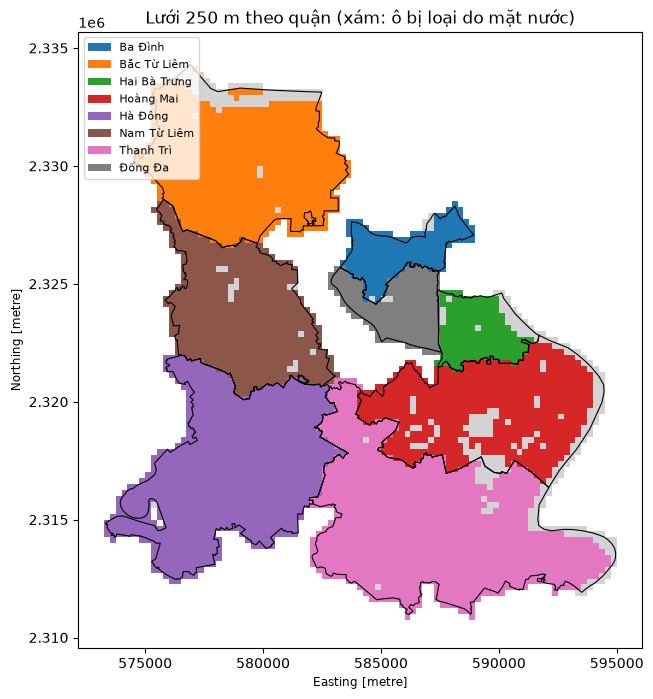

In [14]:
# Bảng kiểm tra theo quận: số ô có gần 16 ô/km2 không, dân số, trạm sạc, ô bị loại
ct = gpd.sjoin(stations, quan[["slug", "geometry"]], predicate="within").groupby("slug").size()
bang = grid.groupby("ten").agg(so_o=("cell_id", "size"), bi_loai=("excluded", "sum"), dan_so=("pop", "sum"),
                               chung_cu=("apt", "mean"), diem_den=("poi", "mean"),
                               d_road_tb=("d_road", "mean"), d_charger_tb=("d_charger", "mean")).round(1)
bang["km2"] = quan.set_index("ten")["km2"]
bang["o_tren_km2"] = (bang["so_o"] / bang["km2"]).round(1)
bang["tram_hien_co"] = quan.set_index("ten")["slug"].map(ct).fillna(0).astype(int)
print(bang.to_string())
print("Tổng ô:", int(bang["so_o"].sum()), "| tổng dân số các ô:", int(bang["dan_so"].sum()))
if not bang["o_tren_km2"].between(14, 20).all():
    print("CẢNH BÁO: có quận lệch xa 16 ô/km2, kiểm tra ranh giới hoặc cách gán ô")

ax = grid.plot(column="ten", categorical=True, legend=True, figsize=(8, 8), linewidth=0, legend_kwds={"loc": "upper left", "fontsize": 8})
grid[grid["excluded"]].plot(ax=ax, color="lightgrey", linewidth=0)
quan.boundary.plot(ax=ax, color="k", linewidth=0.8)
ax.set_title("Lưới 250 m theo quận (xám: ô bị loại do mặt nước)")

## 5. Chuẩn hóa về thang 0-1

Cắt ở phân vị 5 và 95 để vài ô cực đoan không làm lệch thang. Dân số, chung cư, điểm đến lệch phải nặng nên mặc định dùng `log1p` trước khi chuẩn hóa (`LOG_TRANSFORM` ở ô Cài đặt). `d_road` đảo chiều (càng gần càng tốt). `d_charger` dùng trần 2 km (xa hơn coi như tốt như nhau). **Ghi các lựa chọn này vào báo cáo.**

**Phạm vi chuẩn hóa (`NORM_SCOPE`):** với `"all"` mọi quận dùng chung mốc phân vị, nên 70 điểm ở Hà Đông và 70 điểm ở Đống Đa là cùng một mức tiềm năng, và có thể xếp hạng toàn thành phố. Với `"district"` mỗi quận có thang riêng, quận nào cũng có ô "tốt nhất", không so sánh được giữa các quận. Các mốc phân vị được lưu vào `BOUNDS` để trò chơi dùng đúng mốc này (bản 1 để trò chơi tự tính lại từ dữ liệu, nhưng khi mỗi lần chỉ nạp một quận thì phải nhận mốc từ notebook).

Trung bình tiêu chí đã chuẩn hóa theo quận (0-1):
              n_pop  n_apt  n_poi  n_road  n_charger
ten                                                 
Ba Đình        0.83   0.55   0.71    0.92       0.47
Bắc Từ Liêm    0.44   0.19   0.25    0.80       0.76
Hai Bà Trưng   0.81   0.63   0.65    0.91       0.46
Hoàng Mai      0.53   0.37   0.29    0.80       0.52
Hà Đông        0.41   0.23   0.16    0.73       0.60
Nam Từ Liêm    0.52   0.38   0.39    0.87       0.36
Thanh Trì      0.30   0.08   0.09    0.52       0.77
Đống Đa        0.97   0.79   0.79    0.94       0.38


array([[<Axes: title={'center': 'n_pop'}>,
        <Axes: title={'center': 'n_apt'}>],
       [<Axes: title={'center': 'n_poi'}>,
        <Axes: title={'center': 'n_road'}>],
       [<Axes: title={'center': 'n_charger'}>, <Axes: >]], dtype=object)

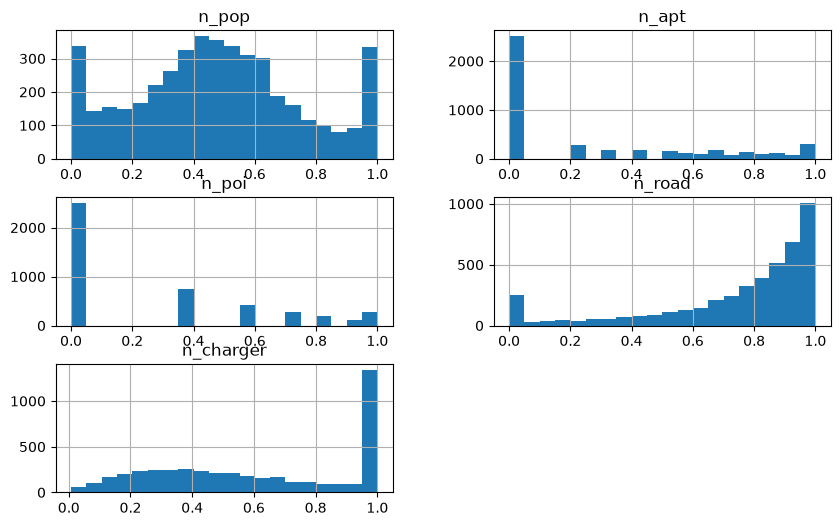

In [15]:
grp = grid["slug"] if NORM_SCOPE == "district" else pd.Series("tat_ca", index=grid.index)
BOUNDS = {}                                           # (nhóm, tiêu chí) -> (mốc dưới, mốc trên), xuất cho trò chơi

def minmax(s, name, lo=5, hi=95):
    out = pd.Series(0.0, index=s.index)
    for gname, idx in grp.groupby(grp).groups.items():
        a, b = np.percentile(s[idx], [lo, hi])
        BOUNDS[(gname, name)] = (float(a), float(b))
        out[idx] = 0.0 if b == a else (s[idx].clip(a, b) - a) / (b - a)
    return out

def prep(s):
    return np.log1p(s) if LOG_TRANSFORM else s

grid["n_pop"] = minmax(prep(grid["pop"]), "pop")
grid["n_apt"] = minmax(prep(grid["apt"]), "apt")
grid["n_poi"] = minmax(prep(grid["poi"]), "poi")
grid["n_road"] = 1 - minmax(grid["d_road"], "road")                # càng gần càng tốt
grid["n_charger"] = np.minimum(grid["d_charger"], 2000) / 2000     # càng xa càng tốt, trần 2 km

NORM = ["n_pop", "n_apt", "n_poi", "n_road", "n_charger"]
print("Trung bình tiêu chí đã chuẩn hóa theo quận (0-1):")
print(grid.groupby("ten")[NORM].mean().round(2).to_string())
grid[NORM].hist(bins=20, figsize=(10, 6))

## 6. Trọng số AHP

So sánh từng cặp tiêu chí theo thang 1, 3, 5, 7, 9 (và nghịch đảo): 3 nghĩa là tiêu chí hàng quan trọng hơn tiêu chí cột "một chút", 9 là "tuyệt đối". Thứ tự: `pop, apt, poi, road, charger`. Cần **CR nhỏ hơn 0,1**; nếu không, xem lại các cặp so sánh mâu thuẫn.

**Ma trận dưới là ma trận của bản 1**, giữ nguyên để kết quả hai bản so sánh được. Nếu đổi, đổi ở cả hai notebook và `tro_choi`.

In [16]:
RI = [0, 0, 0.58, 0.90, 1.12, 1.24, 1.32, 1.41, 1.45, 1.49]

def ahp(M):
    M = np.array(M, dtype=float)
    n = len(M)
    vals, vecs = np.linalg.eig(M)
    k = np.argmax(vals.real)
    w = np.abs(vecs[:, k].real)
    w = w / w.sum()
    ci = (vals[k].real - n) / (n - 1)
    return w, (ci / RI[n - 1] if RI[n - 1] else 0)

def geo_mean(matrices):
    return np.exp(np.mean(np.log(np.array(matrices)), axis=0))

M = [
    [1,   2,   3,   3,   2],
    [1/2, 1,   2,   2,   1],
    [1/3, 1/2, 1,   1,   1/2],
    [1/3, 1/2, 1,   1,   1/2],
    [1/2, 1,   2,   2,   1],
]
w, cr = ahp(M)
print("Trọng số:", {k: round(float(v), 3) for k, v in zip(["pop", "apt", "poi", "road", "charger"], w)})
print("CR =", round(cr, 3), "(đạt nếu < 0.1)")

Trọng số: {'pop': 0.369, 'apt': 0.206, 'poi': 0.109, 'road': 0.109, 'charger': 0.206}
CR = 0.003 (đạt nếu < 0.1)


## 7. Chấm điểm, độ nhạy, kiểm chứng

- **Chấm điểm:** tổng có trọng số các tiêu chí đã chuẩn hóa, ô `excluded` bị loại. Có hai thứ hạng: `rank` (trong quận, khớp nút "Hiện top 10" của trò chơi) và `rank_city` (toàn bộ các quận đã chạy).
- **Độ nhạy:** nhiễu trọng số cộng trừ 20% một nghìn lần, đếm số lần mỗi ô vào top 10 **của quận** (`top10_freq`) và top 10 **của cả thành phố** (`top10_freq_city`). Ô vào top 10 trên 80% số lần là vị trí vững.
- **Kiểm chứng:** tính lại điểm chỉ từ bốn tiêu chí đầu (bỏ `n_charger`, vì trạm đang có bị phạt điểm giả tạo), rồi xem các trạm hiện có nằm ở phân vị nào, **theo từng quận**. Phân vị cao nghĩa là mô hình nhận ra đúng các khu hợp lý. Nếu thấp, hãy thảo luận nguyên nhân trong báo cáo.

In [17]:
X = grid[NORM].values
grid["score"] = X @ w
grid.loc[grid["excluded"], "score"] = np.nan
grid["rank_city"] = grid["score"].rank(ascending=False, method="min")
grid["rank"] = grid.groupby("slug")["score"].rank(ascending=False, method="min")

# Độ nhạy: 1000 bộ trọng số nhiễu +-20%, tính một lần cho mọi ô
rng = np.random.default_rng(42)
ok = ~grid["excluded"].values
N = 1000
Wp = w * rng.uniform(0.8, 1.2, size=(N, len(w)))
Wp = Wp / Wp.sum(axis=1, keepdims=True)
slug_ok = grid.loc[ok, "slug"].values
Xok = X[ok]
hits_d = np.zeros(ok.sum())                            # vào top 10 của quận
hits_c = np.zeros(ok.sum())                            # vào top 10 của cả thành phố
for b in range(0, N, 100):                             # chia lô 100 bộ trọng số để không tốn RAM khi có hàng chục nghìn ô
    S = Xok @ Wp[b:b + 100].T                          # (số ô hợp lệ, số bộ trọng số trong lô)
    for s_ in DISTRICTS:
        ii = np.where(slug_ok == s_)[0]
        k = min(10, len(ii))
        if k:
            top = np.argpartition(-S[ii], k - 1, axis=0)[:k]
            np.add.at(hits_d, ii[top].ravel(), 1)
    top = np.argpartition(-S, 9, axis=0)[:10]
    np.add.at(hits_c, top.ravel(), 1)

grid["top10_freq"] = np.nan
grid["top10_freq_city"] = np.nan
grid.loc[ok, "top10_freq"] = hits_d / N
grid.loc[ok, "top10_freq_city"] = hits_c / N

vung = (grid["top10_freq"] > 0.8).groupby(grid["ten"]).sum().astype(int)
print("Số ô vào top 10 của quận trên 80% số lần thử:")
print(vung.to_string())
print("Số ô vào top 10 của cả thành phố trên 80% số lần thử:", int((grid["top10_freq_city"] > 0.8).sum()))

# Kiểm chứng bằng trạm sạc đang có (mọi trạm trong vùng, tính phân vị trên cả thành phố)
st = gpd.read_file("du_lieu/hn/charging_all.gpkg").to_crs(CRS)
w4 = w[:4] / w[:4].sum()
grid["demand"] = grid[NORM[:4]].values @ w4
grid.loc[grid["excluded"], "demand"] = np.nan
grid["demand_pct"] = grid["demand"].rank(pct=True)
j = gpd.sjoin(st, grid[["cell_id", "ten", "demand_pct", "geometry"]], predicate="within")
kc = j.groupby("ten")["demand_pct"].agg(so_tram="size", pv_tb="mean").round(2)
print("\nPhân vị trung bình của các ô có trạm sạc, theo quận:")
print(kc.to_string())
print("Toàn vùng:", round(j["demand_pct"].mean(), 2), "(0,5 là ngẫu nhiên; càng cao càng tốt)")

Số ô vào top 10 của quận trên 80% số lần thử:
ten
Ba Đình         10
Bắc Từ Liêm      9
Hai Bà Trưng    10
Hoàng Mai        8
Hà Đông          8
Nam Từ Liêm      8
Thanh Trì       10
Đống Đa          7
Số ô vào top 10 của cả thành phố trên 80% số lần thử: 9

Phân vị trung bình của các ô có trạm sạc, theo quận:
              so_tram  pv_tb
ten                         
Ba Đình             6   0.94
Bắc Từ Liêm         6   0.73
Hai Bà Trưng        9   0.96
Hoàng Mai          23   0.79
Hà Đông            14   0.61
Nam Từ Liêm        43   0.69
Thanh Trì           7   0.65
Đống Đa             5   0.98
Toàn vùng: 0.75 (0,5 là ngẫu nhiên; càng cao càng tốt)


## 8. Tổng hợp theo quận, đề xuất cho cả Hà Nội, xuất báo cáo

Đây là phần **đề xuất cho cả khu vực**. Vì mặc định các quận dùng chung thang điểm, ta có thể xếp hạng ô trên toàn thành phố và so sánh các quận với nhau:

- **Bảng tổng hợp quận:** điểm trung bình, số ô từ mức "Tốt" (65 điểm) trở lên, số trạm đang có và dân số trên mỗi trạm. Quận có nhiều ô tốt nhưng ít trạm là nơi nên ưu tiên đầu tư.
- **Top 10 toàn thành phố** và **top 3 mỗi quận**, kèm tọa độ để tra Google Maps.
- Bản đồ tương tác, biểu đồ so sánh quận và biểu đồ độ nhạy.

Các file trong `ket_qua/` đều có tiền tố `hn_` để không đè lên kết quả của bản 1. Mở rộng cả Hà Nội (30 quận huyện thị xã): thêm các dòng vào `DISTRICTS`; mỗi quận được tải và lưu riêng nên làm dần từng đợt được.

Xếp hạng quận theo điểm trung bình:
            ten  so_o  diem_tb  diem_cao_nhat  o_tot  dan_so  ty_le_o_tot_%  tram_hien_co  dan_so_moi_tram
0       Đống Đa   177     79.0           90.9    171  534687           96.6             5         106937.0
1  Hai Bà Trưng   144     76.7           93.7    122  379989           84.7             9          42221.0
2       Ba Đình   173     70.0           89.1    120  331485           69.4             5          66297.0
3     Hoàng Mai   552     53.7           85.5    130  426711           23.6            23          18553.0
4   Bắc Từ Liêm   716     49.0           85.6     70  305665            9.8             6          50944.0
5   Nam Từ Liêm   541     48.4           81.3     41  267792            7.6            42           6376.0
6       Hà Đông   861     42.0           79.6     62  370479            7.2            13          28498.0
7     Thanh Trì  1017     35.9           77.9     24  273767            2.4             7          39110.0



,rank_city,ten,rank,cell_id,score,top10_freq_city,top10_freq,pop,apt,poi,d_road,d_charger,lat,lon
3307,1.0,Hai Bà Trưng,1.0,3307,0.937037,1.000,1.0,4162.016602,30.0,7.0,18.073278,1389.902174,20.99771,105.84309
3371,2.0,Hai Bà Trưng,2.0,3371,0.927091,1.000,1.0,4027.787598,37.0,7.0,82.156310,1330.663281,20.99770,105.84549
3432,3.0,Hai Bà Trưng,3.0,3432,0.916286,1.000,1.0,2582.289062,41.0,8.0,145.360471,1317.004740,20.99768,105.84790
3494,4.0,Hai Bà Trưng,4.0,3494,0.914101,1.000,1.0,3870.404297,28.0,4.0,17.392307,1350.310409,20.99767,105.85031
3240,5.0,Đống Đa,1.0,3240,0.908546,1.000,1.0,3884.200195,23.0,4.0,7.081024,1296.434397,20.99772,105.84068
3495,6.0,Hai Bà Trưng,5.0,3495,0.908015,0.996,1.0,3907.307861,40.0,6.0,14.824062,1108.089666,20.99993,105.85032
3241,7.0,Đống Đa,2.0,3241,0.907739,0.998,1.0,4199.798340,26.0,6.0,52.066419,1125.555790,20.99998,105.84070
3671,8.0,Hai Bà Trưng,6.0,3671,0.904086,0.951,1.0,2695.272461,42.0,8.0,63.015154,1111.358258,21.00215,105.85755
3308,9.0,Hai Bà Trưng,7.0,3308,0.903740,0.946,1.0,4138.215332,36.0,7.0,171.339112,1156.007163,20.99997,105.84310
2828,10.0,Đống Đa,3.0,2828,0.900357,0.391,1.0,3143.846924,19.0,9.0,91.039234,1191.335822,21.02265,105.82398


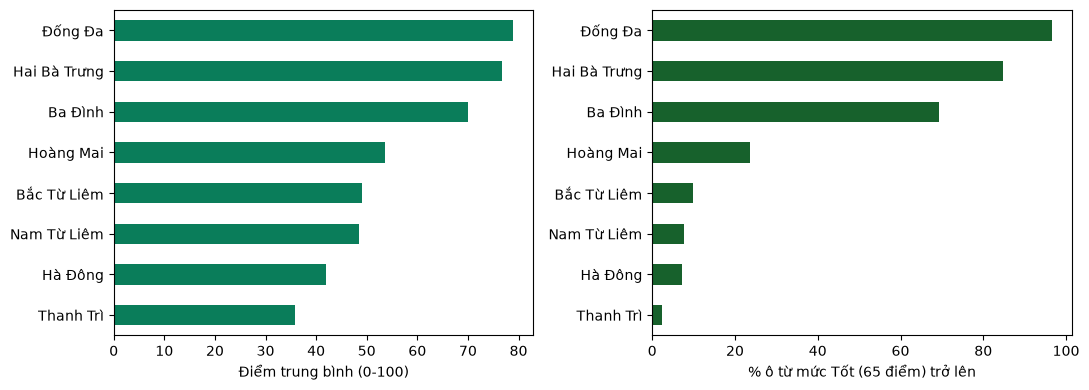

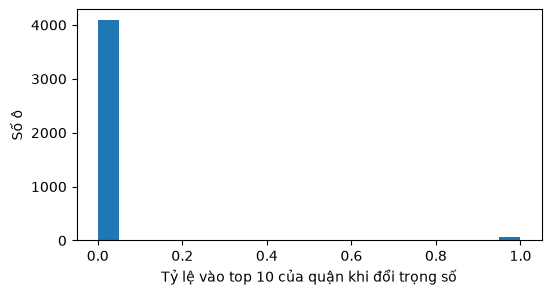

In [18]:
c4326 = grid.geometry.centroid.to_crs(4326)
grid["lat"], grid["lon"] = c4326.y.round(5), c4326.x.round(5)

# --- Bảng tổng hợp theo quận ---
okc = grid[~grid["excluded"]]
tong = okc.groupby(["slug", "ten"]).agg(so_o=("cell_id", "size"), diem_tb=("score", lambda s: 100 * s.mean()),
                                        diem_cao_nhat=("score", lambda s: 100 * s.max()),
                                        o_tot=("score", lambda s: int((100 * s >= 65).sum())),
                                        dan_so=("pop", "sum")).reset_index()
tong["ty_le_o_tot_%"] = (100 * tong["o_tot"] / tong["so_o"]).round(1)
tong["tram_hien_co"] = tong["slug"].map(ct).fillna(0).astype(int)
tong["dan_so_moi_tram"] = (tong["dan_so"] / tong["tram_hien_co"].replace(0, np.nan)).round(0)
tong[["diem_tb", "diem_cao_nhat"]] = tong[["diem_tb", "diem_cao_nhat"]].round(1)
tong["dan_so"] = tong["dan_so"].round(0).astype(int)
tong = tong.sort_values("diem_tb", ascending=False).reset_index(drop=True)
tong.drop(columns="slug").to_csv("ket_qua/hn_tong_hop_quan.csv", index=False, encoding="utf-8-sig")
print("Xếp hạng quận theo điểm trung bình:")
print(tong.drop(columns="slug").to_string())

# --- Top 10 toàn thành phố và top 3 mỗi quận ---
cols = ["rank_city", "ten", "rank", "cell_id", "score", "top10_freq_city", "top10_freq",
        "pop", "apt", "poi", "d_road", "d_charger", "lat", "lon"]
top10 = grid.nsmallest(10, "rank_city").copy()
top10[cols].to_csv("ket_qua/hn_top10_toan_thanh.csv", index=False, encoding="utf-8-sig")
top3 = grid[grid["rank"] <= 3].sort_values(["ten", "rank"])
top3[cols].to_csv("ket_qua/hn_top3_moi_quan.csv", index=False, encoding="utf-8-sig")

# --- Bản đồ tương tác ---
m = grid.to_crs(4326).explore(
    column="score", cmap="YlOrRd", tiles="OpenStreetMap",
    tooltip=["ten", "rank", "rank_city", "score", "pop", "apt", "poi", "d_road", "d_charger"],
    missing_kwds={"color": "lightgrey"}, style_kwds={"weight": 0.3, "fillOpacity": 0.6},
)
quan.to_crs(4326).explore(m=m, color="#10231a", style_kwds={"fill": False, "weight": 2})
top10.to_crs(4326).explore(m=m, color="#0b3d91", style_kwds={"fill": False, "weight": 3})
m.save("ket_qua/hn_ban_do.html")

# --- Biểu đồ so sánh quận và độ nhạy ---
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
tong.set_index("ten")["diem_tb"][::-1].plot.barh(ax=ax[0], color="#0a7d5a")
ax[0].set_xlabel("Điểm trung bình (0-100)")
ax[0].set_ylabel("")
tong.set_index("ten")["ty_le_o_tot_%"][::-1].plot.barh(ax=ax[1], color="#17612c")
ax[1].set_xlabel("% ô từ mức Tốt (65 điểm) trở lên")
ax[1].set_ylabel("")
plt.tight_layout()
plt.savefig("ket_qua/hn_so_sanh_quan.png", dpi=150, bbox_inches="tight")

plt.figure(figsize=(6, 3))
plt.hist(grid["top10_freq"].dropna(), bins=20)
plt.xlabel("Tỷ lệ vào top 10 của quận khi đổi trọng số")
plt.ylabel("Số ô")
plt.savefig("ket_qua/hn_do_nhay.png", dpi=150, bbox_inches="tight")

print("\nTop 10 toàn thành phố:")
top10[cols]

## 9. Xuất dữ liệu cho trò chơi nhiều quận

Ghi vào `tro_choi_hn/data/`:

| File | Nội dung | Khi nào nạp |
|---|---|---|
| `hn.js` | ranh giới các quận, thống kê từng quận, mọi trạm sạc, top 10 toàn thành phố, trọng số | mở trang |
| `<mã quận>.js` | các ô 250 m của một quận và mốc chuẩn hóa `lh` | **chỉ khi bấm vào quận đó** |

Chia file như vậy để trang mở nhanh và không phải nạp hàng nghìn ô của mọi quận cùng lúc; thêm quận mới chỉ thêm một file. Dùng thẻ `<script>` thay vì `fetch` nên mở thẳng bằng `file://` vẫn chạy (trình duyệt chặn `fetch` cho `file://`). Sau khi chạy xong, mở `tro_choi_hn/index.html` rồi nhấn Ctrl + F5. Ô này cũng in phân bố 6 mức điểm theo quận để bạn kiểm tra ngưỡng màu `CUT` trong `index.html` (mặc định 20, 35, 50, 65, 80).

In [19]:
g4326 = grid.to_crs(4326)
gname = lambda slug: slug if NORM_SCOPE == "district" else "tat_ca"
K_OF = {}                                              # cell_id -> số thứ tự trong file của quận (để trò chơi mở đúng ô)

for slug, info in DISTRICTS.items():
    idx = grid.index[grid["slug"] == slug]
    cells = []
    for k, (i, geom, r) in enumerate(zip(idx, g4326.geometry.loc[idx], grid.loc[idx].itertuples())):
        ring = list(geom.exterior.coords)[:4]
        cen = geom.centroid
        cells.append({
            "c": [round(cen.y, 5), round(cen.x, 5)],
            "p": [round(v, 5) for lon, lat in ring for v in (lat, lon)],
            "v": [round(r.pop, 1), int(r.apt), int(r.poi), round(r.d_road), round(r.d_charger)],
            "x": int(r.excluded),
        })
        K_OF[i] = k
    lh = [[round(BOUNDS[(gname(slug), n)][0], 6), round(BOUNDS[(gname(slug), n)][1], 6)] for n in ("pop", "apt", "poi", "road")]
    body = {"lh": lh, "cells": cells}
    with open(f"{OUT}/data/{slug}.js", "w", encoding="utf-8") as f:
        f.write(f"(window.HN_CELLS=window.HN_CELLS||{{}})[{json.dumps(slug)}]=" + json.dumps(body, ensure_ascii=False, separators=(",", ":")) + ";")
    print(f"{info['ten']:<14} {len(cells):>5} ô -> {OUT}/data/{slug}.js")

# File tổng quan cho cả Hà Nội
q4326 = quan.to_crs(4326).set_index("slug")
tt = tong.set_index("slug")
districts = []
for slug, info in DISTRICTS.items():
    geom = q4326.loc[slug, "geometry"].simplify(0.0003)
    districts.append({
        "slug": slug, "ten": info["ten"], "km2": float(q4326.loc[slug, "km2"]),
        "geom": json.loads(gpd.GeoSeries([geom]).to_json())["features"][0]["geometry"],
        "st": {"n": int(tt.loc[slug, "so_o"]), "mean": float(tt.loc[slug, "diem_tb"]), "best": float(tt.loc[slug, "diem_cao_nhat"]),
               "good": int(tt.loc[slug, "o_tot"]), "pop": int(tt.loc[slug, "dan_so"]), "stations": int(tt.loc[slug, "tram_hien_co"])},
    })
st4326 = gpd.read_file("du_lieu/hn/charging_all.gpkg").to_crs(4326)
top_city = [{"slug": r.slug, "ten": r.ten, "k": K_OF[r.cell_id], "lat": r.lat, "lon": r.lon, "score": round(100 * r.score, 1),
             "rank": int(r.rank_city)} for r in grid.nsmallest(10, "rank_city").itertuples()]
hn = {
    "log": bool(LOG_TRANSFORM),
    "scope": NORM_SCOPE,
    "weights": dict(zip(["pop", "apt", "poi", "road", "charger"], [round(float(x), 4) for x in w])),
    "districts": districts,
    "stations": [[round(p.y, 5), round(p.x, 5)] for p in st4326.geometry],
    "top_city": top_city,
}
with open(f"{OUT}/data/hn.js", "w", encoding="utf-8") as f:
    f.write("window.HN_DATA=" + json.dumps(hn, ensure_ascii=False, separators=(",", ":")) + ";")
print(f"\nTổng {len(grid)} ô, {len(st4326)} trạm sạc -> {OUT}/data/hn.js")

# Xem trước phân bố 6 mức điểm theo quận (thang 0-100, cùng ngưỡng với index.html)
CUT = [20, 35, 50, 65, 80]
LEVELS = ["Thấp", "Trung bình thấp", "Trung bình", "Trung bình tốt", "Tốt", "Rất tốt"]
d = grid.dropna(subset=["score"]).copy()
d["muc"] = pd.Categorical(np.digitize(d["score"] * 100, CUT), categories=range(6)).rename_categories(LEVELS)
print("\nSố ô theo mức điểm và quận:")
print(pd.crosstab(d["ten"], d["muc"]).assign(Tong=lambda t: t.sum(axis=1)).to_string())

Bắc Từ Liêm      791 ô -> tro_choi_hn/data/bac_tu_liem.js
Nam Từ Liêm      555 ô -> tro_choi_hn/data/nam_tu_liem.js
Hà Đông          862 ô -> tro_choi_hn/data/ha_dong.js
Ba Đình          179 ô -> tro_choi_hn/data/ba_dinh.js
Đống Đa          179 ô -> tro_choi_hn/data/dong_da.js
Hai Bà Trưng     174 ô -> tro_choi_hn/data/hai_ba_trung.js
Hoàng Mai        674 ô -> tro_choi_hn/data/hoang_mai.js
Thanh Trì       1086 ô -> tro_choi_hn/data/thanh_tri.js

Tổng 4500 ô, 329 trạm sạc -> tro_choi_hn/data/hn.js

Số ô theo mức điểm và quận:
muc           Thấp  Trung bình thấp  Trung bình  Trung bình tốt  Tốt  Rất tốt  Tong
ten                                                                                
Ba Đình          0                0          12              41   86       34   173
Bắc Từ Liêm      0               46         398             202   58       12   716
Hai Bà Trưng     0                0           2              20   61       61   144
Hoàng Mai        1               60         168  